# Protótipo: estimativa da taxa de aprovação dos anos finais em Goiás

**Projeto Integrador de Inteligência Artificial · UEG Trindade · Sistemas de Informação · 2026/2**
João Manoel Silva Morais · Hayyra Eduarda Rocha · Ruan Silva Carvalho · Pedro Lucas Hipólito de Oliveira · Prof. Rafael Viana

Este notebook demonstra a solução proposta no relatório: uma **árvore de decisão para regressão** que estima a taxa de aprovação dos anos finais do Ensino Fundamental (6º ao 9º ano) de cada escola e usa o **resíduo** (taxa real − taxa estimada) para apontar escolas que aprovam menos do que escolas de perfil parecido.

Roteiro:
1. Carregar e limpar os dados
2. Preparar os atributos de entrada
3. Linha de base, regressão linear e árvore de decisão
4. Avaliação (MAE, RMSE, R² e erro nas escolas abaixo de 95%)
5. Interpretação da árvore
6. Lista de escolas em alerta
7. Dificuldades e limitações

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict, train_test_split
from sklearn.tree import DecisionTreeRegressor, export_text

import prototipo as p  # funções do protótipo (src/prototipo.py)

pd.set_option("display.max_colwidth", 60)
plt.rcParams["figure.dpi"] = 110

## 1. Carregar e limpar os dados

A base original veio em PDF e foi convertida para CSV (`dados/02_educacao_regressao.csv`). Na limpeza:
- retiramos as **2 escolas com 0%** de aprovação, prováveis erros de registro;
- retiramos a **única escola federal**, porque não há como aprender um padrão com um exemplo só.

In [2]:
dados = p.carregar_dados()
dados.head()

Base: 1742 escolas | removidas 2 com 0% e 1 federal | restam 1739


,ano,codigo_municipio,municipio,codigo_escola,escola,localizacao,dependencia_administrativa,aprovacao_anos_iniciais_pct,aprovacao_ensino_medio_pct,aprovacao_anos_finais_pct
0,2025,5200050,Abadia de Goiás,52040127,COLEGIO ESTADUAL QUILOMBOLA MANOEL LIBANIO DA SILVA,Urbana,Estadual,NaN,100.0,100.0
1,2025,5200050,Abadia de Goiás,52074820,ESCOLA MUNICIPAL PAULINO INACIO ROSA,Urbana,Municipal,NaN,NaN,99.3
2,2025,5200050,Abadia de Goiás,52092712,ESC MUL PROFESSOR NELI ANTONIO DOS SANTOS,Urbana,Municipal,99.6,NaN,98.6
3,2025,5200100,Abadiânia,52043223,COLEGIO ESTADUAL OSORIO RODRIGUES CAMARGO,Urbana,Estadual,NaN,96.7,98.9
4,2025,5200100,Abadiânia,52043487,COLEGIO ESTADUAL DE EDUCACAO DO CAMPO ANDRE GAUDIE FLEUR...,Rural,Estadual,NaN,98.0,100.0


In [3]:
y_total = dados.aprovacao_anos_finais_pct
print(f"Média: {y_total.mean():.1f}% | mediana: {y_total.median():.0f}%")
print(f"Escolas com 100%: {(y_total == 100).mean():.0%}")
print(f"Escolas abaixo de 95%: {(y_total < 95).sum()} ({(y_total < 95).mean():.0%})")
dados.groupby("dependencia_administrativa").aprovacao_anos_finais_pct.agg(
    escolas="count", media="mean", abaixo_de_95=lambda s: (s < 95).sum()).round(1)

Média: 98.6% | mediana: 100%
Escolas com 100%: 53%
Escolas abaixo de 95%: 140 (8%)


,escolas,media,abaixo_de_95
dependencia_administrativa,,,
Estadual,837,99.3,18
Municipal,456,97.0,96
Privada,446,98.8,26


A variável-alvo está concentrada perto de 100% (**efeito teto**). Por isso, além do erro médio, o protótipo mede o erro **nas escolas abaixo de 95%**, que são as que a gestão precisa encontrar.

## 2. Atributos de entrada

| Atributo | Como foi preparado |
|---|---|
| Rede administrativa | duas colunas 0/1 (`rede_municipal`, `rede_privada`); estadual é a referência |
| Localização | `rural` = 1 ou 0 |
| Aprovação nos anos iniciais | valor da taxa; `-1` quando a escola não oferece a etapa |
| Aprovação no ensino médio | valor da taxa; `-1` quando a escola não oferece a etapa |
| Etapa oferecida | `oferece_anos_iniciais` e `oferece_ensino_medio` (0/1) |
| Município (agrupado) | `escolas_no_municipio`: quantas escolas o município tem na base |

A ausência da taxa não é preenchida com a média: ela vira informação (a escola não oferece a etapa). Árvores não precisam de normalização.

In [4]:
X, y = p.preparar_atributos(dados)
X.head()

,rede_municipal,rede_privada,rural,oferece_anos_iniciais,aprov_anos_iniciais,oferece_ensino_medio,aprov_ensino_medio,escolas_no_municipio
0,0,0,0,0,-1.0,1,100.0,3
1,1,0,0,0,-1.0,0,-1.0,3
2,1,0,0,1,99.6,0,-1.0,3
3,0,0,0,0,-1.0,1,96.7,4
4,0,0,1,0,-1.0,1,98.0,4


## 3. Treinamento

Separamos **80% das escolas para treino e 20% para teste**, mantendo a proporção de cada rede. Comparamos quatro estimativas:
- **Sempre 100%** e **média do treino**: estimativas ingênuas, que qualquer modelo precisa superar;
- **Regressão linear**;
- **Árvore de decisão**, com profundidade máxima e mínimo de escolas por folha escolhidos por **validação cruzada (5 partes)** só no treino.

In [5]:
Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.2, random_state=p.SEMENTE, stratify=dados.dependencia_administrativa)

busca = p.busca_arvore().fit(Xtr, ytr)
arvore = busca.best_estimator_
print("Melhores parâmetros:", busca.best_params_)

previsoes = {
    "Sempre 100%": np.full(len(yte), 100.0),
    "Média do treino": np.full(len(yte), ytr.mean()),
    "Regressão linear": np.clip(LinearRegression().fit(Xtr, ytr).predict(Xte), 0, 100),
    "Árvore de decisão": arvore.predict(Xte),
}
tab_teste = pd.DataFrame({k: p.metricas(yte, v) for k, v in previsoes.items()}).T
tab_teste.round(2)

Melhores parâmetros: {'max_depth': 6, 'min_samples_leaf': 10}


,MAE,RMSE,R2,MAE_abaixo_95,escolas_abaixo_95
Sempre 100%,1.57,3.50,-0.25,10.43,27.0
Média do treino,1.82,3.14,-0.00,9.05,27.0
Regressão linear,1.37,2.40,0.41,5.84,27.0
Árvore de decisão,1.19,2.16,0.52,4.77,27.0


## 4. Avaliação mais robusta: validação cruzada

O conjunto de teste tem só cerca de 27 escolas abaixo de 95%, então o resultado acima depende da divisão sorteada. Para uma avaliação mais confiável, usamos **validação cruzada aninhada**: cada escola é estimada por um modelo que **não a viu** no treino, e os parâmetros da árvore são escolhidos de novo dentro de cada rodada.

In [6]:
cv = KFold(5, shuffle=True, random_state=p.SEMENTE)
fora_da_amostra = {
    "Sempre 100%": np.full(len(y), 100.0),
    "Média do treino": cross_val_predict(DecisionTreeRegressor(max_depth=1, min_samples_leaf=len(y)), X, y, cv=cv),
    "Regressão linear": np.clip(cross_val_predict(LinearRegression(), X, y, cv=cv), 0, 100),
    "Árvore de decisão": cross_val_predict(p.busca_arvore(), X, y, cv=cv),
}
tab_cv = pd.DataFrame({k: p.metricas(y, v) for k, v in fora_da_amostra.items()}).T
tab_cv.round(2)

,MAE,RMSE,R2,MAE_abaixo_95,escolas_abaixo_95
Sempre 100%,1.42,3.45,-0.20,10.13,140.0
Média do treino,1.80,3.15,-0.00,8.72,140.0
Regressão linear,1.36,2.54,0.35,5.93,140.0
Árvore de decisão,1.32,2.52,0.36,5.87,140.0


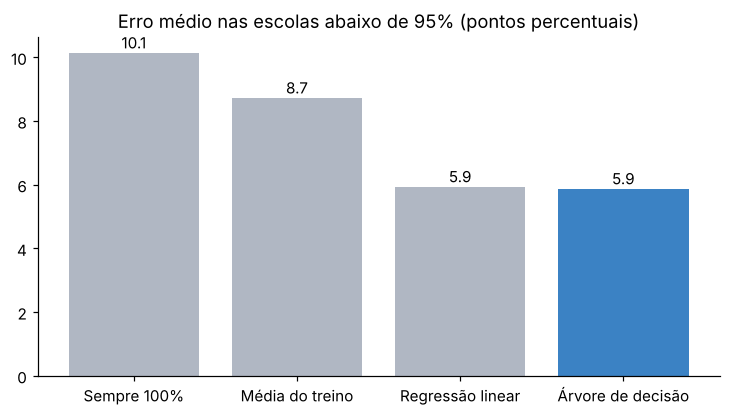

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
t = tab_cv["MAE_abaixo_95"]
ax.bar(t.index, t.values, color=[p.AZUL if k == "Árvore de decisão" else p.CINZA for k in t.index])
for i, v in enumerate(t.values):
    ax.text(i, v + 0.15, f"{v:.1f}", ha="center")
ax.set_title("Erro médio nas escolas abaixo de 95% (pontos percentuais)")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Leitura dos resultados**
- "Sempre 100%" tem MAE geral baixo, mas erra cerca de **10 pontos** justamente nas escolas abaixo de 95%. Isso confirma o efeito teto descrito no relatório.
- A **árvore** e a **regressão linear** reduzem esse erro para cerca de **6 pontos** e explicam cerca de **35% da variação** entre escolas (R² ≈ 0,35).
- Na divisão de teste a árvore foi claramente melhor; na validação cruzada as duas ficam **próximas**, com leve vantagem da árvore. A escolha da árvore se sustenta principalmente pela **interpretabilidade** e pelo tratamento natural dos dados ausentes, não por uma grande diferença de erro.

## 5. Interpretação da árvore

Uma árvore com profundidade 3 mostra as regras principais. Cada caixa mostra quantas escolas chegam ali e a taxa estimada (média dessas escolas). Quanto mais escuro o azul, mais baixa a taxa.

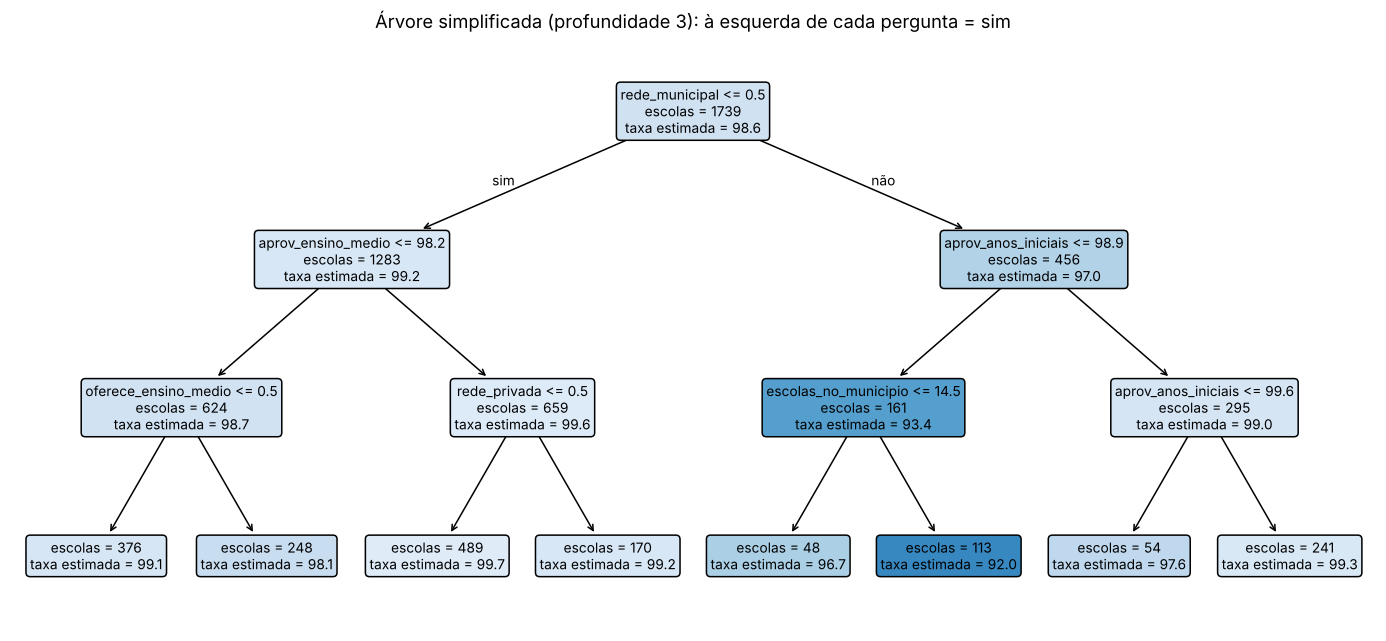

In [8]:
simples = DecisionTreeRegressor(max_depth=3, min_samples_leaf=30, random_state=p.SEMENTE).fit(X, y)
fig, ax = plt.subplots(figsize=(16, 7))
p.desenhar_arvore(simples, list(X.columns), ax)
plt.show()

O caminho mais crítico é: **escola municipal → aprovação nos anos iniciais até 98,9% → município com mais de 14 escolas**. Esse grupo (113 escolas) tem taxa estimada de **92%**, bem abaixo da média geral de 98,6%. A regra confirma o que a análise da base mostrou: o risco se concentra na rede municipal com anos iniciais mais fracos.

In [9]:
final = p.busca_arvore().fit(X, y).best_estimator_
importancia = pd.Series(final.feature_importances_, index=X.columns).sort_values(ascending=False)
importancia.round(3)

aprov_anos_iniciais      0.519
escolas_no_municipio     0.229
rede_municipal           0.161
aprov_ensino_medio       0.063
oferece_ensino_medio     0.014
oferece_anos_iniciais    0.008
rede_privada             0.006
rural                    0.000
dtype: float64

Os atributos mais usados pela árvore final são a **aprovação nos anos iniciais**, o **número de escolas do município** (que indica cidades maiores, como Planaltina, Valparaíso e Formosa) e a **rede municipal**. Localização rural não foi usada. Isso indica **associação**, não causa (ver a questão para reflexão no relatório).

## 6. Lista de escolas em alerta

O resíduo é **taxa real − taxa estimada**, calculado com as previsões fora da amostra. Um resíduo de **−5 pontos ou menos** indica que a escola aprova bem menos do que escolas parecidas e entra na lista de alerta.

In [10]:
res = dados[["codigo_escola", "escola", "municipio", "dependencia_administrativa", "localizacao"]].copy()
res["taxa_real"] = y
res["taxa_estimada"] = fora_da_amostra["Árvore de decisão"].round(1)
res["residuo"] = (res.taxa_real - res.taxa_estimada).round(1)
alertas = res[res.residuo <= p.LIMIAR_ALERTA].sort_values("residuo")
print(f"Escolas em alerta: {len(alertas)}")
print(f"Todas com aprovação real abaixo de 95%? {(alertas.taxa_real < 95).all()}")
print(f"Das {(y < 95).sum()} escolas abaixo de 95%, a lista encontra {len(alertas)} ({len(alertas) / (y < 95).sum():.0%})")
alertas.head(15)

Escolas em alerta: 58
Todas com aprovação real abaixo de 95%? True
Das 140 escolas abaixo de 95%, a lista encontra 58 (41%)


,codigo_escola,escola,municipio,dependencia_administrativa,localizacao,taxa_real,taxa_estimada,residuo
1124,52093700,ESCOLA MARIA TEIXEIRA,Luziânia,Privada,Urbana,72.7,97.5,-24.8
1697,52047644,ESCOLA MUNICIPAL CASINHA FELIZ,Valparaíso de Goiás,Municipal,Urbana,68.6,90.4,-21.8
1535,52075427,ESCOLA MUNICIPAL DE ENSINO,Santo Antônio do Descoberto,Municipal,Urbana,72.9,93.3,-20.4
1071,52053253,COLEGIO PROFESSOR JOBIM,Jataí,Privada,Urbana,81.3,99.9,-18.6
367,52012824,ESC MUL PROFA JANDIRA DA SILVA AIRES,Campos Belos,Municipal,Urbana,80.6,97.0,-16.4
1372,52092631,ESCOLA MUNICIPAL PROFESSORA JULIA DA SILVA OLIVEIRA,Planaltina,Municipal,Urbana,80.7,97.1,-16.4
1370,52088936,ESCOLA MUNICIPAL DARCY RIBEIRO,Planaltina,Municipal,Urbana,77.4,93.0,-15.6
33,52081850,COLEGIO ESTADUAL PIAGET,Águas Lindas de Goiás,Estadual,Urbana,82.8,96.6,-13.8
317,52066770,ESC MUNICIPAL RURAL ENTRONCAMENTO,Cachoeira Alta,Municipal,Rural,86.5,99.9,-13.4
539,52046982,ESCOLA MUNICIPAL PROFESSOR JOAQUIM MOREIRA,Formosa,Municipal,Urbana,83.0,96.4,-13.4


In [11]:
alertas.dependencia_administrativa.value_counts()

dependencia_administrativa
Municipal    42
Privada      11
Estadual      5
Name: count, dtype: int64

Todas as escolas apontadas realmente têm aprovação abaixo de 95%, e a maioria é municipal. A lista não encontra todas as escolas críticas: as que ficam de fora têm aprovação baixa, mas parecida com a de escolas do mesmo perfil, então o modelo já esperava uma taxa mais baixa para elas.

**Atenção:** a lista é um **sinal de alerta para investigar**, não um diagnóstico nem uma avaliação da escola.

## 7. Dificuldades e limitações

- **Conversão dos dados:** a base veio em PDF, com colunas divididas em páginas diferentes e nomes cortados; foi preciso reconstruir a tabela (`src/extrair_pdf.py`).
- **Efeito teto:** com 53% das escolas em 100%, o erro médio sozinho engana; foi necessário medir o erro nas escolas abaixo de 95%.
- **Poucas escolas críticas:** só 140 escolas abaixo de 95%, o que deixa a avaliação sensível à divisão treino/teste; por isso usamos validação cruzada.
- **Poucos atributos:** sem matrículas, nível socioeconômico ou histórico, o modelo explica cerca de 35% da variação.
- **Árvore x regressão linear:** o ganho de precisão da árvore é pequeno; a vantagem principal está nas regras interpretáveis.
- **Município:** usamos o número de escolas do município como forma agregada; ele funciona como indicador de cidades maiores, não como causa.

**Melhorias:** incluir mais anos de dados, matrículas e o Inse do INEP, e testar Random Forest.